# 🐱🐶 Rede Neural Convolucional (CNN) — Classificando Gatos e Cachorros

**Aula prática de Machine Learning — UNINASSAU**

Neste notebook vamos treinar, do zero, uma **Rede Neural Convolucional** capaz de olhar para uma foto e dizer se ela mostra um **gato** ou um **cachorro**.

### O que você vai aprender
1. Como imagens viram números que a rede consegue processar
2. Como organizar as bases de **treinamento**, **validação** e **teste**
3. O que é **data augmentation** (aumento de dados) e por que ele ajuda
4. Como montar uma CNN com camadas de **convolução**, **pooling** e **densas**
5. Como treinar, acompanhar as curvas de aprendizado e identificar **overfitting**
6. Como avaliar o modelo com **acurácia**, **precisão**, **recall**, **F1** e **matriz de confusão**
7. Como o **número de épocas** e a **taxa de aprendizado** afetam o resultado (experimento)
8. Como testar o modelo com **as suas próprias fotos** (projeto da disciplina)

### Roteiro
| Seção | Conteúdo |
|---|---|
| 1 | Preparação do ambiente |
| 2 | Carregando e conhecendo a base de dados |
| 3 | Preparando as imagens (geradores e data augmentation) |
| 4 | Construindo a CNN |
| 5 | Treinando a rede |
| 6 | Analisando o treinamento |
| 7 | Avaliando na base de teste |
| 8 | Classificando uma imagem individual |
| 9 | Salvando o modelo |
| 10 | 🧪 Experimento: comparando as 9 configurações e escolhendo o modelo |
| 11 | **Projeto da disciplina: testando com a sua base de imagens** |

### 🧪 O experimento
Vamos comparar **9 configurações** de treinamento, combinando:
- **Épocas:** 10, 15 e 20
- **Taxa de aprendizado:** 0,1 · 0,01 · 0,001

Para cada configuração: altere `EPOCAS` e `LEARNING_RATE` na célula de configurações e execute o notebook até a **Seção 9**. Os resultados são guardados automaticamente em uma tabela (Seção 7.5). As instruções completas estão no **PDF do experimento**.

> 💡 **Dica:** execute as células **em ordem**, de cima para baixo (`Shift + Enter`). Se algo der errado, use *Ambiente de execução → Reiniciar e executar tudo*.

---
## 1. Preparação do ambiente

Vamos importar as bibliotecas que serão usadas:

- **TensorFlow / Keras** → biblioteca de Deep Learning onde montamos e treinamos a rede.
- **NumPy** → manipulação de vetores e matrizes (uma imagem é uma matriz de números!).
- **Matplotlib** → gráficos e exibição de imagens.
- **scikit-learn** → métricas de avaliação (acurácia, matriz de confusão).

Também fixamos uma **semente aleatória** (`seed`). Redes neurais começam com pesos aleatórios; fixar a semente faz com que os resultados fiquem mais parecidos entre execuções.

In [1]:
import os
import zipfile
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
import pandas as pd

# Semente para tornar os resultados reprodutíveis
SEED = 42
tf.keras.utils.set_random_seed(SEED)

print("Versão do TensorFlow:", tf.__version__)
print("GPU disponível:", "Sim ✅" if tf.config.list_physical_devices('GPU') else "Não (vai rodar na CPU, só fica mais lento)")

Versão do TensorFlow: 2.21.0


GPU disponível: Não (vai rodar na CPU, só fica mais lento)


### ⚙️ Configurações gerais

Deixamos todos os caminhos e parâmetros principais **em um só lugar**. Se o nome do seu arquivo ou das pastas for diferente, altere **apenas esta célula**.

- `TAMANHO_IMG`: todas as imagens serão redimensionadas para **64 × 64 pixels**. Imagens menores = treino mais rápido (mas com menos detalhes).
- `BATCH_SIZE`: quantas imagens a rede vê de cada vez antes de ajustar os pesos.
- `EPOCAS` e `LEARNING_RATE`: **são os parâmetros do experimento**. Mude aqui a cada execução.

In [2]:
# ---------------- CONFIGURACOES (Colab ou execucao local) ----------------
PASTA_PROJETO = next(
    (pasta for pasta in (Path.cwd(), *Path.cwd().parents)
     if (pasta / "dataset_gato_cachorro.zip").is_file()),
    Path("/content"),
)
ARQUIVO_ZIP = str(PASTA_PROJETO / "dataset_gato_cachorro.zip")
PASTA_BASE = str(PASTA_PROJETO / "dataset")

PASTA_TREINO = f"{PASTA_BASE}/training_set"
PASTA_VALID = f"{PASTA_BASE}/validation_set"
PASTA_TESTE = f"{PASTA_BASE}/test_set"

TAMANHO_IMG = (64, 64)
BATCH_SIZE = 16
EPOCAS = 10
LEARNING_RATE = 0.001


---
## 2. Carregando e conhecendo a base de dados

### 2.1 Descompactando o arquivo
Antes de executar, **envie o arquivo `.zip` da base** para o Colab: clique no ícone de pasta 📁 na barra lateral esquerda e arraste o arquivo para dentro de `/content`.

A estrutura esperada é:
```
dataset/
├── training_set/
│   ├── cachorro/   (fotos de cachorros)
│   └── gato/       (fotos de gatos)
├── validation_set/ (opcional)
│   ├── cachorro/
│   └── gato/
└── test_set/
    ├── cachorro/
    └── gato/
```
> 📌 **Importante:** o Keras descobre as classes **pelo nome das pastas**. Cada subpasta (`gato`, `cachorro`) vira uma classe. Por isso não precisamos de nenhum arquivo de rótulos!

In [3]:
if not os.path.exists(ARQUIVO_ZIP):
    print(f"⚠️ Arquivo {ARQUIVO_ZIP} não encontrado. Envie o .zip para o Colab (ícone de pasta à esquerda).")
else:
    with zipfile.ZipFile(ARQUIVO_ZIP, "r") as arquivo_zip:
        arquivo_zip.extractall(str(PASTA_PROJETO))
    print("✅ Base descompactada em", PASTA_BASE)

✅ Base descompactada em C:\Users\lneto\Treinamento-IA-ML\cnn-gato-cachorro\dataset


### 2.2 Quantas imagens temos?
Uma boa prática é sempre **conferir o tamanho da base** e se as classes estão **balanceadas** (quantidades parecidas de gatos e cachorros). Uma base desbalanceada pode fazer a rede "preferir" a classe mais frequente.

In [4]:
def contar_imagens(pasta):
    # Mostra quantas imagens existem em cada subpasta (classe)
    if not os.path.isdir(pasta):
        print("  (pasta não encontrada: tudo bem! Vamos separar 20% do treinamento para validação na Seção 3)")
        return
    for classe in sorted(os.listdir(pasta)):
        caminho = os.path.join(pasta, classe)
        if os.path.isdir(caminho):
            print(f"  {classe:10s}: {len(os.listdir(caminho)):5d} imagens")

print("TREINAMENTO:"); contar_imagens(PASTA_TREINO)
print("VALIDAÇÃO:");   contar_imagens(PASTA_VALID)
print("TESTE:");       contar_imagens(PASTA_TESTE)

TREINAMENTO:
  cachorro  :  2000 imagens
  gato      :  2000 imagens
VALIDAÇÃO:
  (pasta não encontrada: tudo bem! Vamos separar 20% do treinamento para validação na Seção 3)
TESTE:
  cachorro  :   500 imagens
  gato      :   500 imagens


### 2.3 Visualizando algumas imagens
Repare que as fotos têm **tamanhos, fundos, poses e iluminação diferentes**. É justamente essa variedade que torna o problema desafiador — e interessante!

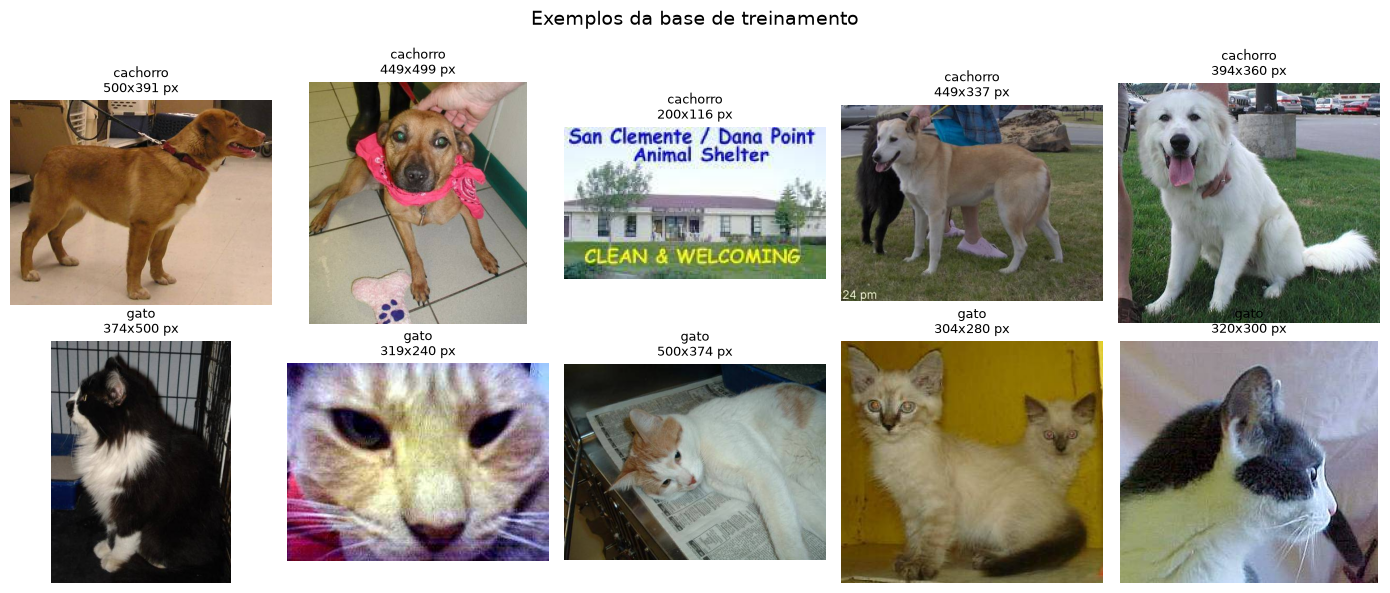

In [5]:
classes = sorted(os.listdir(PASTA_TREINO))   # ['cachorro', 'gato']

fig, eixos = plt.subplots(2, 5, figsize=(14, 6))
for linha, classe in enumerate(classes):
    pasta_classe = os.path.join(PASTA_TREINO, classe)
    exemplos = random.sample(os.listdir(pasta_classe), 5)
    for coluna, nome_arquivo in enumerate(exemplos):
        imagem = load_img(os.path.join(pasta_classe, nome_arquivo))
        eixos[linha, coluna].imshow(imagem)
        eixos[linha, coluna].set_title(f"{classe}\n{imagem.size[0]}x{imagem.size[1]} px", fontsize=9)
        eixos[linha, coluna].axis("off")
plt.suptitle("Exemplos da base de treinamento", fontsize=14)
plt.tight_layout()
plt.show()

### 2.4 Para o computador, uma imagem é uma matriz de números
Uma imagem colorida tem **3 canais** (Vermelho, Verde e Azul — **RGB**). Cada pixel de cada canal é um número de **0 a 255**.

Uma imagem de 64 × 64 pixels colorida é, portanto, um bloco de **64 × 64 × 3 = 12.288 números**. É isso que entra na rede.

Formato da imagem (altura, largura, canais): (64, 64, 3)
Menor valor: 0.0 | Maior valor: 255.0

Canto superior esquerdo (5x5 pixels) do canal VERMELHO:
[[206 212 222 227 231]
 [206 212 222 228 234]
 [206 212 222 228 232]
 [209 215 221 221 226]
 [209 215 220 222 216]]


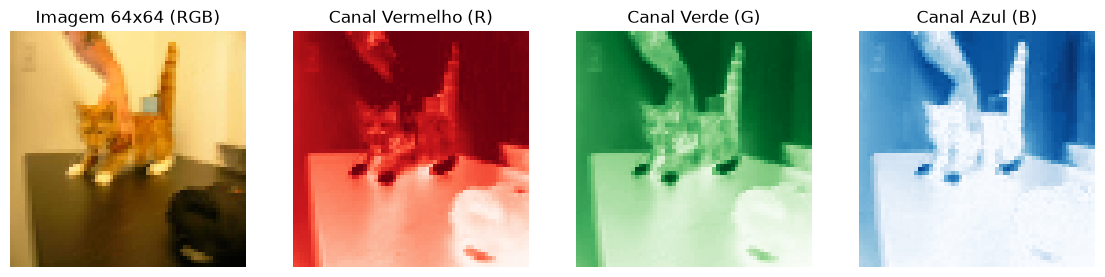

In [6]:
exemplo = load_img(os.path.join(PASTA_TREINO, classes[1], os.listdir(os.path.join(PASTA_TREINO, classes[1]))[0]),
                   target_size=TAMANHO_IMG)
matriz = img_to_array(exemplo)

print("Formato da imagem (altura, largura, canais):", matriz.shape)
print("Menor valor:", matriz.min(), "| Maior valor:", matriz.max())
print("\nCanto superior esquerdo (5x5 pixels) do canal VERMELHO:")
print(matriz[:5, :5, 0].astype(int))

fig, eixos = plt.subplots(1, 4, figsize=(14, 3.5))
eixos[0].imshow(exemplo); eixos[0].set_title("Imagem 64x64 (RGB)")
for i, (nome, mapa) in enumerate([("Vermelho (R)", "Reds"), ("Verde (G)", "Greens"), ("Azul (B)", "Blues")]):
    eixos[i + 1].imshow(matriz[:, :, i], cmap=mapa); eixos[i + 1].set_title(f"Canal {nome}")
for e in eixos: e.axis("off")
plt.show()

---
## 3. Preparando as imagens: geradores e *data augmentation*

### 3.1 Por que três bases?
| Base | Para que serve | Analogia |
|---|---|---|
| **Treinamento** | A rede aprende (ajusta seus pesos) com estas imagens | As listas de exercícios |
| **Validação** | Acompanhamos o desempenho **durante** o treino para detectar overfitting e ajustar hiperparâmetros | Os simulados |
| **Teste** | Avaliação **final**, com imagens que a rede nunca viu | A prova |

> ⚠️ A base de teste **não pode** ser usada para tomar decisões durante o treino — senão a "prova" deixa de ser justa.

### 3.2 O que é *data augmentation*?
Temos uma quantidade limitada de fotos. Para a rede não **decorar** as imagens, criamos **variações aleatórias** delas a cada época: pequenas rotações, espelhamento, zoom, deslocamentos...

Um gato espelhado **continua sendo um gato**! Assim a rede aprende características mais gerais (orelhas, focinho, formato) em vez de detalhes de uma foto específica.

> 📌 O aumento de dados é aplicado **somente no treinamento**. Validação e teste usam as imagens originais.

### 3.3 Normalização (`rescale = 1./255`)
Os pixels vão de 0 a 255. Dividindo por 255, eles passam a ficar entre **0 e 1**, o que deixa o treinamento mais estável e rápido.

In [7]:
# Se a pasta de validação não existir, separamos automaticamente 20% do treino para validação
tem_pasta_validacao = os.path.isdir(PASTA_VALID)
fracao_validacao = 0.0 if tem_pasta_validacao else 0.2

# Gerador de TREINAMENTO: normaliza + aplica data augmentation
gerador_treinamento = ImageDataGenerator(rescale=1./255,          # pixels de 0-255 para 0-1
                                         rotation_range=7,         # rotaciona até 7 graus
                                         horizontal_flip=True,     # espelha horizontalmente
                                         shear_range=0.2,          # "inclina" a imagem
                                         height_shift_range=0.07,  # desloca verticalmente até 7%
                                         zoom_range=0.2,           # zoom de até 20%
                                         validation_split=fracao_validacao)

# Gerador de VALIDAÇÃO e TESTE: apenas normaliza (sem augmentation!)
gerador_avaliacao = ImageDataGenerator(rescale=1./255, validation_split=fracao_validacao)

### 3.4 Vendo o *data augmentation* em ação
Abaixo, a **mesma foto** passa várias vezes pelo gerador de treinamento. Cada execução gera uma versão um pouco diferente.

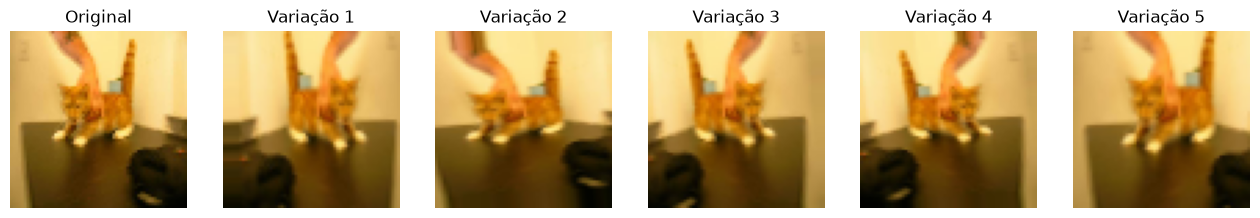

In [8]:
original = img_to_array(exemplo)

fig, eixos = plt.subplots(1, 6, figsize=(16, 3))
eixos[0].imshow(original.astype("uint8")); eixos[0].set_title("Original")
for i in range(1, 6):
    variacao = gerador_treinamento.random_transform(original)
    eixos[i].imshow(variacao.astype("uint8")); eixos[i].set_title(f"Variação {i}")
for e in eixos: e.axis("off")
plt.show()

### 3.5 Criando as bases a partir das pastas
O método `flow_from_directory` lê as imagens das pastas **em lotes** (sem carregar tudo na memória de uma vez), redimensiona para 64 × 64 e cria os rótulos a partir do nome das pastas.

- `class_mode='binary'` → temos **duas classes**, então o rótulo é **0 ou 1**.
- `shuffle=False` na validação → mantém a ordem das imagens (útil para comparar previsões com rótulos reais).

In [9]:
if tem_pasta_validacao:
    base_treinamento = gerador_treinamento.flow_from_directory(PASTA_TREINO, target_size=TAMANHO_IMG,
                                                               batch_size=BATCH_SIZE, class_mode="binary", seed=SEED)
    base_validacao = gerador_avaliacao.flow_from_directory(PASTA_VALID, target_size=TAMANHO_IMG,
                                                           batch_size=BATCH_SIZE, class_mode="binary", shuffle=False)
else:
    print("Sem pasta de validação → separando 20% de cada classe do treinamento para validação.\n")
    base_treinamento = gerador_treinamento.flow_from_directory(PASTA_TREINO, target_size=TAMANHO_IMG,
                                                               batch_size=BATCH_SIZE, class_mode="binary",
                                                               subset="training", seed=SEED)
    base_validacao = gerador_avaliacao.flow_from_directory(PASTA_TREINO, target_size=TAMANHO_IMG,
                                                           batch_size=BATCH_SIZE, class_mode="binary",
                                                           subset="validation", shuffle=False)

print("\nMapeamento das classes:", base_treinamento.class_indices)

Sem pasta de validação → separando 20% de cada classe do treinamento para validação.

Found 3200 images belonging to 2 classes.


Found 800 images belonging to 2 classes.



Mapeamento das classes: {'cachorro': 0, 'gato': 1}


> 📌 **Guarde este mapeamento!** As pastas são ordenadas em ordem alfabética: `cachorro → 0` e `gato → 1`.
> Isso significa que a saída da rede será interpretada como **"probabilidade de ser GATO"**.

---
## 4. Construindo a Rede Neural Convolucional

### Arquitetura
```
Imagem 64x64x3
   │
   ├─► Conv2D (32 filtros 3x3, ReLU)  ──► 62x62x32   ┐
   ├─► MaxPooling (2x2)               ──► 31x31x32   ┘ Bloco convolucional 1
   │
   ├─► Conv2D (32 filtros 3x3, ReLU)  ──► 29x29x32   ┐
   ├─► MaxPooling (2x2)               ──► 14x14x32   ┘ Bloco convolucional 2
   │
   ├─► Flatten                        ──► 6.272 valores (vetor)
   ├─► Dense 128 (ReLU)                                ┐
   ├─► Dense 128 (ReLU)                                ┘ Classificador
   └─► Dense 1 (Sigmoid)              ──► probabilidade de ser GATO (0 a 1)
```

### O papel de cada camada
| Camada | O que faz | Intuição |
|---|---|---|
| **Conv2D** | Desliza pequenos filtros (3 × 3) pela imagem, gerando *mapas de características* | Detecta padrões: bordas, texturas, depois orelhas, olhos... |
| **ReLU** | Zera valores negativos: `max(0, x)` | Introduz não-linearidade, permitindo aprender padrões complexos |
| **MaxPooling2D** | Pega o maior valor de cada janela 2 × 2 | Reduz o tamanho pela metade e mantém o que é mais importante |
| **Flatten** | Transforma o bloco 3D em um vetor 1D | "Desenrola" a imagem para entrar nas camadas densas |
| **Dense** | Neurônios totalmente conectados | Combina as características para tomar a decisão |
| **Sigmoid** | Comprime a saída para o intervalo 0 a 1 | Vira uma **probabilidade** |

### De onde vêm os tamanhos?
- Um filtro 3 × 3 **sem preenchimento (padding)** "perde" 1 pixel em cada borda: 64 → **62**.
- O MaxPooling 2 × 2 divide pela metade: 62 → **31**.
- Segunda convolução: 31 → **29**; segundo pooling: 29 → **14** (arredonda para baixo).
- Flatten: 14 × 14 × 32 = **6.272** valores.

> 📌 Montamos a rede dentro de uma **função** (`criar_modelo`). Assim, sempre que quisermos treinar uma configuração nova, criamos uma rede **nova**, com pesos iniciais aleatórios, em vez de continuar treinando a anterior.

In [10]:
def criar_modelo():
    modelo = Sequential(name="cnn_gato_cachorro")

    # Entrada: imagens 64x64 com 3 canais (RGB)
    modelo.add(Input(shape=(TAMANHO_IMG[0], TAMANHO_IMG[1], 3)))

    # ---- Bloco convolucional 1: extrai características simples (bordas, cores, texturas) ----
    modelo.add(Conv2D(32, (3, 3), activation="relu"))   # 32 filtros 3x3 -> 62x62x32
    modelo.add(MaxPooling2D(pool_size=(2, 2)))          # reduz pela metade -> 31x31x32

    # ---- Bloco convolucional 2: combina as características anteriores (formas mais complexas) ----
    modelo.add(Conv2D(32, (3, 3), activation="relu"))   # -> 29x29x32
    modelo.add(MaxPooling2D(pool_size=(2, 2)))          # -> 14x14x32

    # ---- Transição: de "imagem" para "vetor" ----
    modelo.add(Flatten())                               # 14*14*32 = 6272 valores

    # ---- Classificador (rede neural densa tradicional) ----
    modelo.add(Dense(units=128, activation="relu"))
    modelo.add(Dense(units=128, activation="relu"))

    # ---- Saída: 1 neurônio com sigmoid = probabilidade de ser GATO ----
    modelo.add(Dense(units=1, activation="sigmoid"))
    return modelo

tf.keras.utils.set_random_seed(SEED)   # mesma inicialização em todas as configurações (comparação justa)
classificador = criar_modelo()
classificador.summary()

Model: "cnn_gato_cachorro"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 829,729 (3.17 MB)

 Trainable params: 829,729 (3.17 MB)

 Non-trainable params: 0 (0.00 B)

### Entendendo a coluna *Param #* (número de parâmetros)
São os **pesos que a rede vai aprender**:

| Camada | Cálculo | Parâmetros |
|---|---|---|
| Conv2D 1 | (3 × 3 × **3** canais + 1 bias) × 32 filtros | 896 |
| Conv2D 2 | (3 × 3 × **32** canais + 1 bias) × 32 filtros | 9.248 |
| Dense 128 | (6.272 + 1) × 128 | 802.944 |
| Dense 128 | (128 + 1) × 128 | 16.512 |
| Dense 1 | (128 + 1) × 1 | 129 |
| **Total** | | **829.729** |

> 🤔 **Para pensar:** cerca de **97% dos parâmetros** estão na primeira camada densa! As camadas convolucionais são muito "econômicas", pois **o mesmo filtro é reaproveitado em toda a imagem**. Essa é uma das grandes vantagens das CNNs.

---
## 5. Treinando a rede

### 5.1 Compilando o modelo
Antes de treinar, definimos três coisas:

- **Função de perda (`loss`)** → mede o quanto a rede está errando. Para duas classes com saída sigmoid usamos a **`binary_crossentropy`**.
- **Otimizador** → o algoritmo que ajusta os pesos para diminuir a perda. Usaremos o **Adam**, uma versão aprimorada do gradiente descendente.
- **Taxa de aprendizado (`LEARNING_RATE`)** → o "tamanho do passo" de cada ajuste. Muito alta: a rede "pula" a solução e pode não aprender nada. Muito baixa: o treino fica lento.
- **Métrica** → o que queremos acompanhar de forma intuitiva: a **acurácia** (percentual de acertos).

In [11]:
print(f"Configuração atual → épocas: {EPOCAS} | taxa de aprendizado: {LEARNING_RATE}")

classificador.compile(optimizer=Adam(learning_rate=LEARNING_RATE),
                      loss="binary_crossentropy",
                      metrics=["accuracy"])

Configuração atual → épocas: 10 | taxa de aprendizado: 0.001


### 5.2 Treinando (`fit`)
- **Época** = a rede viu **todas** as imagens de treino uma vez.
- Em cada época aparecem 4 números: `loss` e `accuracy` (treino) e `val_loss` e `val_accuracy` (validação).
- A rede treina **exatamente** o número de épocas definido em `EPOCAS`, para podermos comparar 10, 15 e 20 épocas no experimento.

⏳ *Este passo pode levar alguns minutos (cerca de 30 a 40 segundos por época).*

In [12]:
historico = classificador.fit(base_treinamento,
                              epochs=EPOCAS,
                              validation_data=base_validacao)

Epoch 1/10


  1/200 ━━━━━━━━━━━━━━━━━━━━ 3:55 1s/step - accuracy: 0.5625 - loss: 0.6931

  3/200 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.5000 - loss: 0.7068

  5/200 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - accuracy: 0.4750 - loss: 0.7069

  7/200 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 0.4911 - loss: 0.7024

  9/200 ━━━━━━━━━━━━━━━━━━━━ 6s 36ms/step - accuracy: 0.4931 - loss: 0.7005

... (1,090 outputs left out)

195/200 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.7494 - loss: 0.5084

197/200 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.7494 - loss: 0.5091

199/200 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.7497 - loss: 0.5088

200/200 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - accuracy: 0.7497 - loss: 0.5080 - val_accuracy: 0.7550 - val_loss: 0.4829


---
## 6. Analisando o treinamento

Os gráficos abaixo mostram como a **acurácia** e a **perda** evoluíram a cada época.

Como interpretar:
- ✅ **Treino e validação melhorando juntos** → a rede está aprendendo de verdade.
- ⚠️ **Treino continua melhorando, mas validação piora** → **overfitting**: a rede está *decorando* as imagens de treino em vez de aprender a generalizar.
- ⚠️ **Os dois estagnados em valores ruins** → **underfitting**: o modelo é simples demais ou precisa de mais treino.

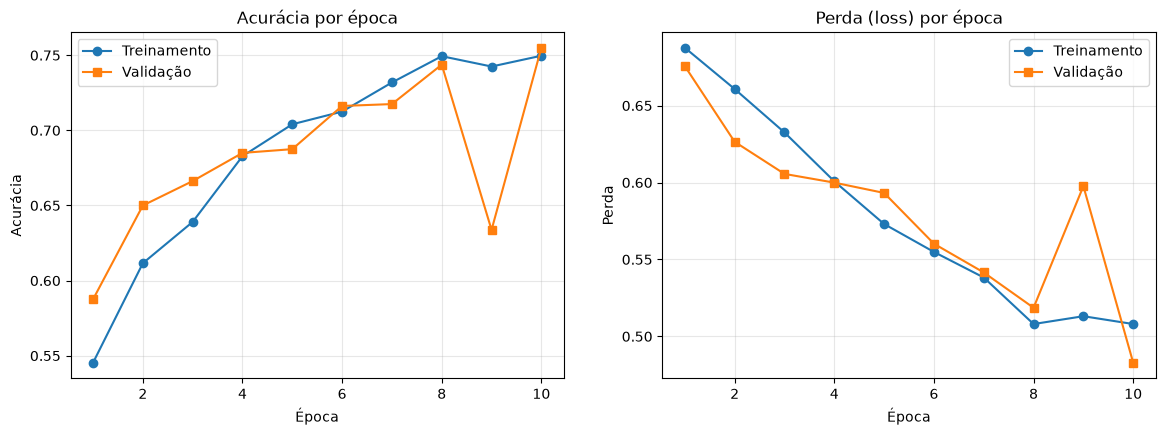

In [13]:
h = historico.history
epocas = range(1, len(h["loss"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

ax1.plot(epocas, h["accuracy"], "o-", label="Treinamento")
ax1.plot(epocas, h["val_accuracy"], "s-", label="Validação")
ax1.set_title("Acurácia por época"); ax1.set_xlabel("Época"); ax1.set_ylabel("Acurácia")
ax1.grid(alpha=0.3); ax1.legend()

ax2.plot(epocas, h["loss"], "o-", label="Treinamento")
ax2.plot(epocas, h["val_loss"], "s-", label="Validação")
ax2.set_title("Perda (loss) por época"); ax2.set_xlabel("Época"); ax2.set_ylabel("Perda")
ax2.grid(alpha=0.3); ax2.legend()

plt.show()

---
## 7. Avaliando na base de teste

Agora vem a "prova final": imagens que a rede **nunca viu**, nem no treino nem na validação.

### 7.1 Carregando a base de teste

In [14]:
base_teste = gerador_avaliacao.flow_from_directory(PASTA_TESTE,
                                                   target_size=TAMANHO_IMG,
                                                   batch_size=BATCH_SIZE,
                                                   class_mode="binary",
                                                   shuffle=False)   # NÃO embaralhar: precisamos da ordem original
print("Mapeamento:", base_teste.class_indices)

Found 1000 images belonging to 2 classes.


Mapeamento: {'cachorro': 0, 'gato': 1}


### 7.2 Fazendo as previsões
A rede devolve, para cada imagem, um número entre 0 e 1 = **probabilidade de ser gato**.

Para transformar isso em uma classe, usamos um **limiar (threshold) de 0,5**:
- probabilidade **> 0,5** → classe **1 (gato)**
- probabilidade **≤ 0,5** → classe **0 (cachorro)**

In [15]:
probabilidades = classificador.predict(base_teste).ravel()   # .ravel() transforma em vetor simples
previsoes = (probabilidades > 0.5).astype(int)              # aplica o limiar de 0,5
reais = base_teste.classes                                  # rótulos verdadeiros (vindos das pastas)

print("Primeiras 10 probabilidades:", np.round(probabilidades[:10], 3))
print("Primeiras 10 previsões     :", previsoes[:10])
print("Primeiros 10 rótulos reais :", reais[:10])

 1/63 ━━━━━━━━━━━━━━━━━━━━ 6s 101ms/step

 5/63 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step 

 8/63 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step

11/63 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step

14/63 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step

17/63 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step

... (14 outputs left out)

62/63 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step


Primeiras 10 probabilidades: [0.284 0.766 0.018 0.307 0.878 0.797 0.435 0.375 0.205 0.07 ]
Primeiras 10 previsões     : [0 1 0 0 1 1 0 0 0 0]
Primeiros 10 rótulos reais : [0 0 0 0 0 0 0 0 0 0]


### 7.3 Acurácia e matriz de confusão
- **Acurácia** = acertos ÷ total de imagens.
- A **matriz de confusão** mostra **onde** a rede erra: quantos cachorros foram confundidos com gatos e vice-versa. A diagonal principal são os acertos.
- O **relatório de classificação** mostra, para cada classe:
  - **Precisão** (*precision*): das imagens que a rede chamou de gato, quantas eram gato? → `VP / (VP + FP)`
  - **Recall** (sensibilidade): de todos os gatos, quantos a rede encontrou? → `VP / (VP + FN)`
  - **F1-score**: média harmônica entre precisão e recall → `2 · P · R / (P + R)`

> No experimento, consideramos **gato como a classe positiva** (rótulo 1).

🎯 Acurácia na base de TESTE: 74.40%



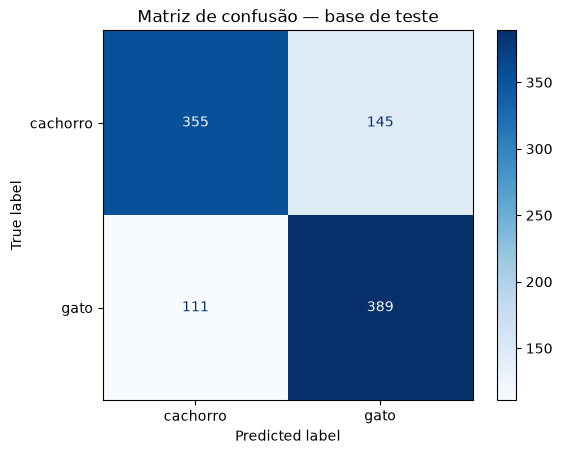

              precision    recall  f1-score   support

    cachorro       0.76      0.71      0.73       500
        gato       0.73      0.78      0.75       500

    accuracy                           0.74      1000
   macro avg       0.75      0.74      0.74      1000
weighted avg       0.75      0.74      0.74      1000



In [16]:
nomes_classes = list(base_teste.class_indices.keys())   # ['cachorro', 'gato']

acuracia = accuracy_score(reais, previsoes)
print(f"🎯 Acurácia na base de TESTE: {acuracia:.2%}\n")

ConfusionMatrixDisplay(confusion_matrix(reais, previsoes), display_labels=nomes_classes).plot(cmap="Blues")
plt.title("Matriz de confusão — base de teste")
plt.show()

print(classification_report(reais, previsoes, target_names=nomes_classes, zero_division=0))

### 7.4 Onde a rede errou?
Olhar os erros é uma das partes **mais importantes** de qualquer projeto de Machine Learning. Muitas vezes descobrimos o motivo: foto escura, animal pequeno no canto, dois animais na mesma imagem, ângulo incomum...

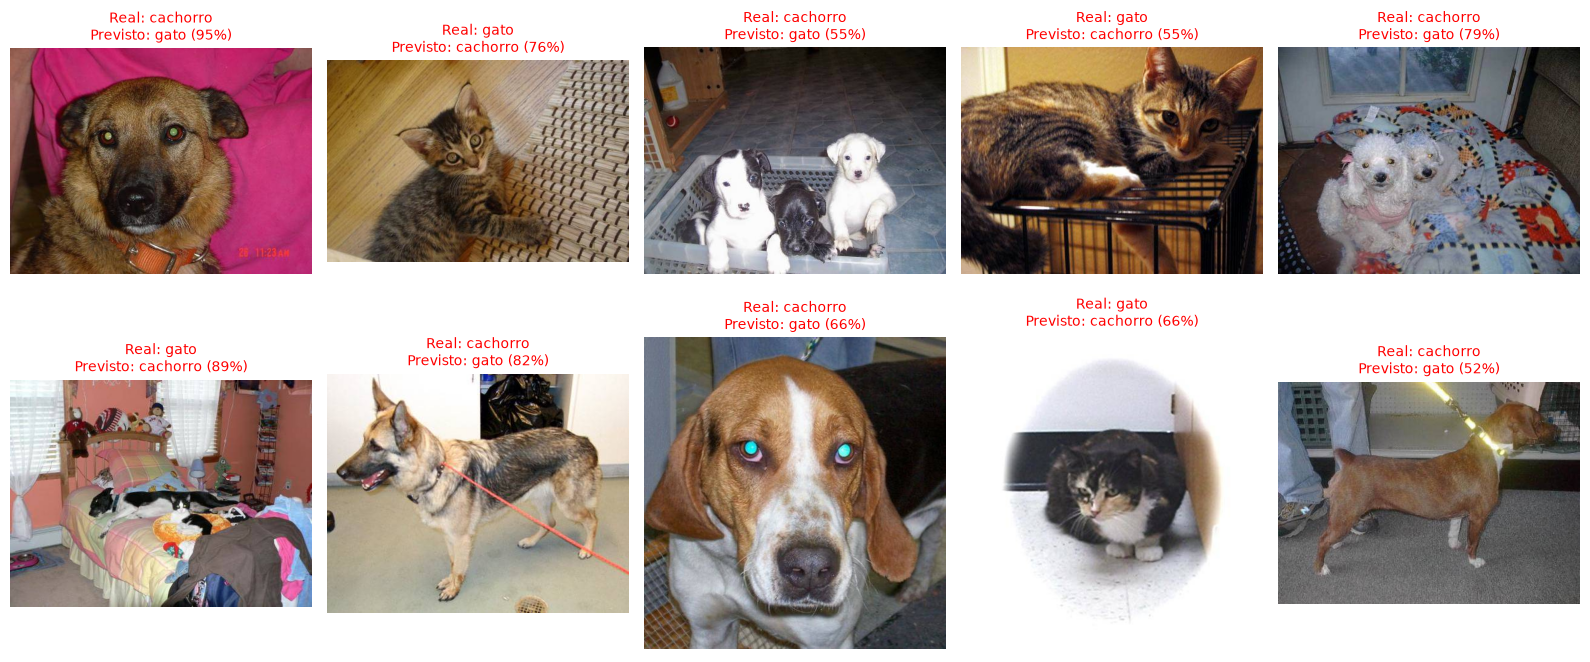

In [17]:
def mostrar_exemplos(base, probabilidades, apenas_erros=True, quantidade=10):
    # Mostra imagens com a classe real, a prevista e a confiança da rede
    nomes = {v: k for k, v in base.class_indices.items()}   # {0: 'cachorro', 1: 'gato'}
    prev = (probabilidades > 0.5).astype(int)
    indices = np.where(prev != base.classes)[0] if apenas_erros else np.arange(len(prev))
    if len(indices) == 0:
        print("Nenhum erro encontrado! 🎉")
        return
    indices = np.random.choice(indices, size=min(quantidade, len(indices)), replace=False)

    colunas = 5
    linhas = int(np.ceil(len(indices) / colunas))
    plt.figure(figsize=(3.2 * colunas, 3.4 * linhas))
    for i, idx in enumerate(indices):
        p = probabilidades[idx]
        confianca = p if prev[idx] == 1 else 1 - p
        acertou = prev[idx] == base.classes[idx]
        plt.subplot(linhas, colunas, i + 1)
        plt.imshow(load_img(base.filepaths[idx]))
        plt.title(f"Real: {nomes[base.classes[idx]]}\nPrevisto: {nomes[prev[idx]]} ({confianca:.0%})",
                  color="green" if acertou else "red", fontsize=10)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

mostrar_exemplos(base_teste, probabilidades, apenas_erros=True)

### 7.5 🧪 Registrando o resultado desta configuração
A célula abaixo guarda as métricas desta execução no arquivo `resultados_experimento.csv`. A cada nova configuração (épocas + taxa de aprendizado), uma nova linha é adicionada. Se você repetir uma configuração, a linha antiga é substituída.

- **Métricas de treino e validação**: valores da **última época**.
- **Métricas de teste**: calculadas na base de teste, com **gato como classe positiva**.

> ⚠️ Os arquivos de `/content` são apagados quando a sessão do Colab termina. **Baixe o CSV** ao final de cada sessão (ícone 📁 → clique com o botão direito → *Fazer download*).

In [18]:
ARQUIVO_RESULTADOS = str(PASTA_PROJETO / "resultados_experimento.csv")

def registrar_resultado(epocas, lr, acc_treino, acc_val, perda_val, reais, previsoes):
    nova_linha = pd.DataFrame([{
        "epocas": epocas,
        "learning_rate": lr,
        "acc_treino": acc_treino,
        "acc_validacao": acc_val,
        "perda_validacao": perda_val,
        "acc_teste": accuracy_score(reais, previsoes),
        "precisao_teste": precision_score(reais, previsoes, zero_division=0),
        "recall_teste": recall_score(reais, previsoes, zero_division=0),
        "f1_teste": f1_score(reais, previsoes, zero_division=0),
    }])
    if os.path.exists(ARQUIVO_RESULTADOS):
        tabela = pd.read_csv(ARQUIVO_RESULTADOS)
        mesma_config = (tabela["epocas"] == epocas) & (tabela["learning_rate"] == lr)
        tabela = pd.concat([tabela[~mesma_config], nova_linha], ignore_index=True)
    else:
        tabela = nova_linha
    tabela = tabela.sort_values(["learning_rate", "epocas"], ascending=[False, True]).reset_index(drop=True)
    tabela.to_csv(ARQUIVO_RESULTADOS, index=False)
    return tabela

tabela = registrar_resultado(EPOCAS, LEARNING_RATE,
                             h["accuracy"][-1], h["val_accuracy"][-1], h["val_loss"][-1],
                             reais, previsoes)
print(f"Configurações registradas: {len(tabela)} de 9\n")
tabela.round(4)

Configurações registradas: 1 de 9



,epocas,learning_rate,acc_treino,acc_validacao,perda_validacao,acc_teste,precisao_teste,recall_teste,f1_teste
0,10,0.001,0.7497,0.755,0.4829,0.744,0.7285,0.778,0.7524


---
## 8. Classificando uma imagem individual

Na vida real, um modelo recebe **uma imagem por vez**. Para isso precisamos repetir **exatamente o mesmo pré-processamento** usado no treino:
1. redimensionar para 64 × 64;
2. converter para matriz de números;
3. dividir por 255;
4. adicionar a dimensão do *lote* (a rede espera um lote de imagens: formato `(1, 64, 64, 3)`).

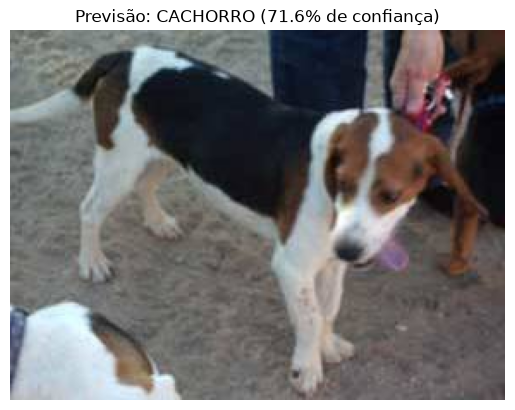

('cachorro', 0.28382283449172974)

In [19]:
nomes_por_indice = {v: k for k, v in base_treinamento.class_indices.items()}   # {0: 'cachorro', 1: 'gato'}

def classificar_imagem(caminho_imagem):
    imagem = load_img(caminho_imagem, target_size=TAMANHO_IMG)   # 1. redimensiona
    x = img_to_array(imagem) / 255.0                             # 2 e 3. matriz normalizada
    x = np.expand_dims(x, axis=0)                                # 4. formato (1, 64, 64, 3)

    prob_gato = classificador.predict(x, verbose=0)[0][0]
    classe = nomes_por_indice[int(prob_gato > 0.5)]
    confianca = prob_gato if prob_gato > 0.5 else 1 - prob_gato

    plt.imshow(load_img(caminho_imagem))
    plt.title(f"Previsão: {classe.upper()} ({confianca:.1%} de confiança)")
    plt.axis("off")
    plt.show()
    return classe, float(prob_gato)

# Testando com uma imagem qualquer da base de teste
pasta_exemplo = os.path.join(PASTA_TESTE, "cachorro")
classificar_imagem(os.path.join(pasta_exemplo, sorted(os.listdir(pasta_exemplo))[0]))

---
## 9. Salvando o modelo treinado

Treinar leva tempo! Salvando o modelo, você pode **reutilizá-lo depois sem treinar de novo**. O nome do arquivo indica a configuração (épocas e taxa de aprendizado), então cada uma das 9 configurações gera o seu próprio arquivo. Na Seção 11 você vai carregar o **modelo selecionado**.

> ⚠️ No Colab, os arquivos de `/content` **são apagados** quando a sessão termina. Baixe o arquivo `.keras` para o seu computador (ou salve no Google Drive).

In [20]:
def caminho_modelo(epocas, lr):
    return str(PASTA_PROJETO / f"modelo_e{epocas}_lr{lr}.keras")   # ex.: /content/modelo_e20_lr0.001.keras

classificador.save(caminho_modelo(EPOCAS, LEARNING_RATE))
print("✅ Modelo salvo em", caminho_modelo(EPOCAS, LEARNING_RATE))

# Para carregar em outro momento (depois de enviar o arquivo para o Colab):
# classificador = tf.keras.models.load_model("/content/modelo_e20_lr0.001.keras")

# Para baixar o arquivo para o seu computador (somente no Colab):
# from google.colab import files
# files.download(caminho_modelo(EPOCAS, LEARNING_RATE))

✅ Modelo salvo em C:\Users\lneto\Treinamento-IA-ML\cnn-gato-cachorro\modelo_e10_lr0.001.keras


---
## 10. 🧪 Experimento: comparando as 9 configurações

Há duas formas de preencher a tabela do experimento:
1. **Manual:** altere `EPOCAS` e `LEARNING_RATE` na célula de configurações e execute o notebook até a Seção 9, repetindo para as 9 combinações. Cada execução adiciona uma linha à tabela (Seção 7.5).
2. **Automática (opcional):** use a célula abaixo para rodar as 9 configurações de uma só vez.

**Truque para economizar tempo:** para cada taxa de aprendizado, treinamos **uma única rede por 20 épocas** e "tiramos uma foto" do modelo nas épocas **10, 15 e 20**. O modelo da época 10 passou exatamente pelo mesmo processo de um treino de 10 épocas, então o resultado é equivalente (podem surgir pequenas diferenças por causa da aleatoriedade do embaralhamento e do data augmentation). Assim treinamos 60 épocas no total em vez de 135.

⏳ **Tempo estimado:** cerca de 40 minutos. Mude `EXECUTAR_GRADE` para `True` para rodar. Os resultados vão para a mesma tabela da Seção 7.5, e os modelos são salvos com os mesmos nomes da Seção 9.

In [21]:
EXECUTAR_GRADE = True            # mude para True para rodar as 9 configurações
GRADE_EPOCAS   = [10, 15, 20]
GRADE_LR       = [0.1, 0.01, 0.001]

class AvaliarNasEpocas(tf.keras.callbacks.Callback):
    # Ao final das épocas escolhidas, avalia na base de teste, registra as métricas e salva o modelo
    def __init__(self, epocas_alvo, lr):
        super().__init__()
        self.epocas_alvo, self.lr = epocas_alvo, lr

    def on_epoch_end(self, epoch, logs=None):
        ep = epoch + 1
        if ep in self.epocas_alvo:
            probs = self.model.predict(base_teste, verbose=0).ravel()
            prev = (probs > 0.5).astype(int)
            registrar_resultado(ep, self.lr, logs["accuracy"], logs["val_accuracy"], logs["val_loss"],
                                base_teste.classes, prev)
            self.model.save(caminho_modelo(ep, self.lr))
            print(f"   ✔ registrado: épocas={ep}, lr={self.lr}, val_acc={logs['val_accuracy']:.4f}")

if EXECUTAR_GRADE:
    for lr in GRADE_LR:
        print(f"\n===== Taxa de aprendizado {lr} =====")
        tf.keras.utils.set_random_seed(SEED)
        modelo = criar_modelo()
        modelo.compile(optimizer=Adam(learning_rate=lr), loss="binary_crossentropy", metrics=["accuracy"])
        modelo.fit(base_treinamento, epochs=max(GRADE_EPOCAS), validation_data=base_validacao,
                   callbacks=[AvaliarNasEpocas(GRADE_EPOCAS, lr)], verbose=2)
    display(pd.read_csv(ARQUIVO_RESULTADOS).round(4))
else:
    print("Grade desativada. Mude EXECUTAR_GRADE para True para rodar as 9 configurações.")


===== Taxa de aprendizado 0.1 =====
Epoch 1/20


200/200 - 10s - 52ms/step - accuracy: 0.5034 - loss: 112.4235 - val_accuracy: 0.5000 - val_loss: 0.6931


Epoch 2/20


200/200 - 9s - 45ms/step - accuracy: 0.4969 - loss: 0.6959 - val_accuracy: 0.5000 - val_loss: 0.6955


Epoch 3/20


200/200 - 9s - 46ms/step - accuracy: 0.4944 - loss: 0.6971 - val_accuracy: 0.5000 - val_loss: 0.6942


... (111 outputs left out)

200/200 - 10s - 50ms/step - accuracy: 0.8100 - loss: 0.4136 - val_accuracy: 0.7487 - val_loss: 0.5213


Epoch 20/20


   ✔ registrado: épocas=20, lr=0.001, val_acc=0.7487
200/200 - 11s - 57ms/step - accuracy: 0.8253 - loss: 0.3828 - val_accuracy: 0.7487 - val_loss: 0.5266


,epocas,learning_rate,acc_treino,acc_validacao,perda_validacao,acc_teste,precisao_teste,recall_teste,f1_teste
0,10,0.100,0.4925,0.5000,0.6939,0.500,0.5000,1.000,0.6667
1,15,0.100,0.5013,0.5000,0.6957,0.500,0.5000,1.000,0.6667
2,20,0.100,0.5019,0.5000,0.6963,0.500,0.0000,0.000,0.0000
3,10,0.010,0.4919,0.5000,0.6932,0.500,0.0000,0.000,0.0000
4,15,0.010,0.4938,0.5000,0.6932,0.500,0.0000,0.000,0.0000
5,20,0.010,0.4963,0.5000,0.6934,0.500,0.0000,0.000,0.0000
6,10,0.001,0.7406,0.7613,0.4848,0.718,0.7455,0.662,0.7013
7,15,0.001,0.7825,0.7287,0.5162,0.749,0.8059,0.656,0.7233
8,20,0.001,0.8253,0.7487,0.5266,0.743,0.8293,0.612,0.7043


### Qual configuração escolher?
A célula abaixo mostra a tabela completa e indica a configuração com **maior acurácia de validação** (desempate: menor perda de validação). Use o arquivo indicado em `MODELO_SELECIONADO` na Seção 11.

In [22]:
tabela = pd.read_csv(ARQUIVO_RESULTADOS)
display(tabela.round(4))

melhor = tabela.sort_values(["acc_validacao", "perda_validacao"], ascending=[False, True]).iloc[0]
print(f"🏆 Melhor configuração na VALIDAÇÃO: épocas={int(melhor.epocas)}, lr={melhor.learning_rate}")
print(f"   → MODELO_SELECIONADO = \"{caminho_modelo(int(melhor.epocas), melhor.learning_rate)}\"")

,epocas,learning_rate,acc_treino,acc_validacao,perda_validacao,acc_teste,precisao_teste,recall_teste,f1_teste
0,10,0.100,0.4925,0.5000,0.6939,0.500,0.5000,1.000,0.6667
1,15,0.100,0.5013,0.5000,0.6957,0.500,0.5000,1.000,0.6667
2,20,0.100,0.5019,0.5000,0.6963,0.500,0.0000,0.000,0.0000
3,10,0.010,0.4919,0.5000,0.6932,0.500,0.0000,0.000,0.0000
4,15,0.010,0.4938,0.5000,0.6932,0.500,0.0000,0.000,0.0000
5,20,0.010,0.4963,0.5000,0.6934,0.500,0.0000,0.000,0.0000
6,10,0.001,0.7406,0.7613,0.4848,0.718,0.7455,0.662,0.7013
7,15,0.001,0.7825,0.7287,0.5162,0.749,0.8059,0.656,0.7233
8,20,0.001,0.8253,0.7487,0.5266,0.743,0.8293,0.612,0.7043


🏆 Melhor configuração na VALIDAÇÃO: épocas=10, lr=0.001
   → MODELO_SELECIONADO = "C:\Users\lneto\Treinamento-IA-ML\cnn-gato-cachorro\modelo_e10_lr0.001.keras"


---
## 11. 📸 Projeto da disciplina: testando com a **sua** base de imagens

Até aqui o modelo foi testado com imagens parecidas com as do treino. Mas será que ele funciona no **mundo real**? Agora é a sua vez de descobrir!

> Antes desta seção, **escolha o melhor modelo** entre as 9 configurações: o de **maior acurácia de validação** (em caso de empate, o de **menor perda de validação**). Não use a base de teste para escolher!

### Etapa 1 — Capture as imagens
- Fotografe **gatos e cachorros** (seus pets, de amigos, vizinhos, na rua...).
- Quantidade: **10 fotos de gatos e 10 fotos de cachorros** (20 no total).
- Varie: ângulos, distâncias, iluminação, ambientes, raças e cores diferentes.
- Formatos aceitos: **JPG** ou **PNG**.
  > 📱 iPhone salva em **HEIC** por padrão, que **não é aceito**. Converta antes ou ative *Ajustes → Câmera → Formatos → Mais Compatível*.

### Etapa 2 — Organize as pastas
Os nomes das pastas devem ser **exatamente** `cachorro` e `gato` (minúsculas, sem acento), iguais aos da base de treino. Assim a rede usa o mesmo mapeamento (`cachorro → 0`, `gato → 1`).
```
minha_base.zip
└── minha_base/
    ├── cachorro/
    │   ├── foto01.jpg
    │   └── ...
    └── gato/
        ├── foto01.jpg
        └── ...
```

### Etapa 3 — Envie e avalie
Compacte a pasta em `minha_base.zip`, envie para o Colab (ícone 📁 à esquerda) e execute as células abaixo.

In [23]:
ARQUIVO_MINHA_BASE = str(PASTA_PROJETO / "minha_base.zip")   # altere se o seu arquivo tiver outro nome

# Modelo selecionado no experimento (maior acurácia de VALIDAÇÃO). Exemplo:
# MODELO_SELECIONADO = "/content/modelo_e20_lr0.001.keras"
melhor_config = pd.read_csv(ARQUIVO_RESULTADOS).sort_values(
    ["acc_validacao", "perda_validacao"], ascending=[False, True]
).iloc[0]
MODELO_SELECIONADO = caminho_modelo(
    int(melhor_config["epocas"]), melhor_config["learning_rate"]
)

if MODELO_SELECIONADO:
    modelo_final = tf.keras.models.load_model(MODELO_SELECIONADO)
    print("✅ Modelo carregado:", MODELO_SELECIONADO)
else:
    modelo_final = classificador
    print(f"Usando o modelo treinado nesta sessão (épocas={EPOCAS}, lr={LEARNING_RATE})")

def encontrar_pasta_com_classes(raiz):
    # Procura, dentro do que foi descompactado, a pasta que contém as subpastas 'gato' e 'cachorro'
    for pasta, subpastas, _ in os.walk(raiz):
        if "__MACOSX" in pasta:
            continue
        if "gato" in subpastas and "cachorro" in subpastas:
            return pasta
    return None

with zipfile.ZipFile(ARQUIVO_MINHA_BASE, "r") as z:
    z.extractall(str(PASTA_PROJETO / "minha_base_extraida"))

PASTA_MINHA_BASE = encontrar_pasta_com_classes(str(PASTA_PROJETO / "minha_base_extraida"))
if PASTA_MINHA_BASE is None:
    print("⚠️ Não encontrei as pastas 'gato' e 'cachorro'. Confira a organização do seu .zip (Etapa 2).")
else:
    print("✅ Pasta encontrada:", PASTA_MINHA_BASE)
    contar_imagens(PASTA_MINHA_BASE)

✅ Modelo carregado: C:\Users\lneto\Treinamento-IA-ML\cnn-gato-cachorro\modelo_e10_lr0.001.keras


✅ Pasta encontrada: C:\Users\lneto\Treinamento-IA-ML\cnn-gato-cachorro\minha_base_extraida
  cachorro  :    10 imagens
  gato      :    10 imagens


A função abaixo faz **exatamente o que fizemos na Seção 7**, só que agrupado em um único passo: carrega a base, faz as previsões, calcula as métricas e mostra a matriz de confusão. Ela é aplicada ao **modelo selecionado**, na base de teste e na sua base.

Found 1000 images belonging to 2 classes.



🎯 Base de teste
   Acurácia : 71.80%
   Precisão : 74.55%   (classe positiva = gato)
   Recall   : 66.20%
   F1-score : 70.13%



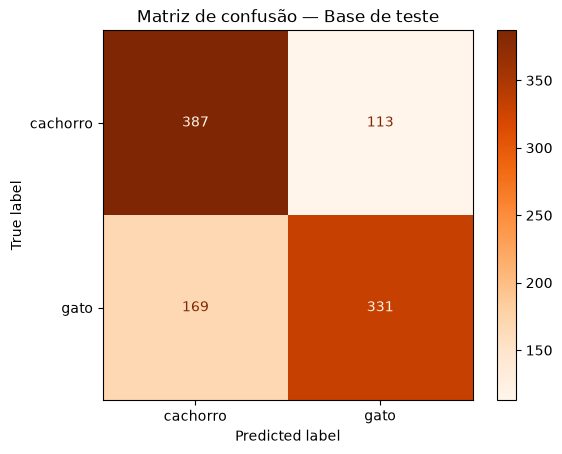

              precision    recall  f1-score   support

    cachorro       0.70      0.77      0.73       500
        gato       0.75      0.66      0.70       500

    accuracy                           0.72      1000
   macro avg       0.72      0.72      0.72      1000
weighted avg       0.72      0.72      0.72      1000

Found 20 images belonging to 2 classes.



🎯 Minha base
   Acurácia : 65.00%
   Precisão : 100.00%   (classe positiva = gato)
   Recall   : 30.00%
   F1-score : 46.15%



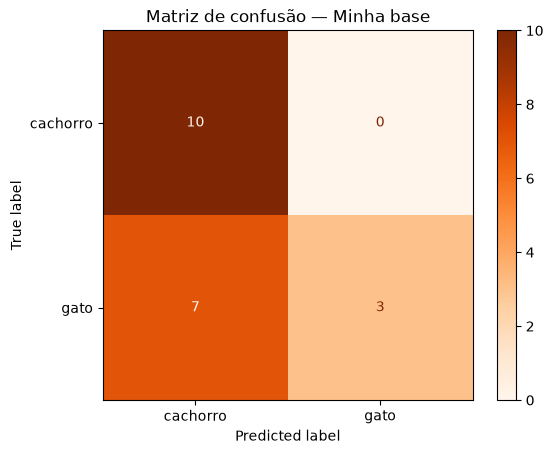

              precision    recall  f1-score   support

    cachorro       0.59      1.00      0.74        10
        gato       1.00      0.30      0.46        10

    accuracy                           0.65        20
   macro avg       0.79      0.65      0.60        20
weighted avg       0.79      0.65      0.60        20

Comparação → Base de teste: 71.80% | Minha base: 65.00%


In [24]:
def avaliar_base(modelo, pasta, titulo="Minha base"):
    base = gerador_avaliacao.flow_from_directory(pasta, target_size=TAMANHO_IMG, batch_size=BATCH_SIZE,
                                                 class_mode="binary", shuffle=False)
    probs = modelo.predict(base, verbose=0).ravel()
    prev = (probs > 0.5).astype(int)
    nomes = list(base.class_indices.keys())

    acc = accuracy_score(base.classes, prev)
    print(f"\n🎯 {titulo}")
    print(f"   Acurácia : {acc:.2%}")
    print(f"   Precisão : {precision_score(base.classes, prev, zero_division=0):.2%}   (classe positiva = gato)")
    print(f"   Recall   : {recall_score(base.classes, prev, zero_division=0):.2%}")
    print(f"   F1-score : {f1_score(base.classes, prev, zero_division=0):.2%}\n")
    ConfusionMatrixDisplay(confusion_matrix(base.classes, prev), display_labels=nomes).plot(cmap="Oranges")
    plt.title(f"Matriz de confusão — {titulo}")
    plt.show()
    print(classification_report(base.classes, prev, target_names=nomes, zero_division=0))
    return base, probs, acc

# Avalia o modelo selecionado na base de teste e na sua base
_, _, acc_teste_final = avaliar_base(modelo_final, PASTA_TESTE, "Base de teste")
base_minha, probs_minha, acc_minha = avaliar_base(modelo_final, PASTA_MINHA_BASE, "Minha base")
print(f"Comparação → Base de teste: {acc_teste_final:.2%} | Minha base: {acc_minha:.2%}")

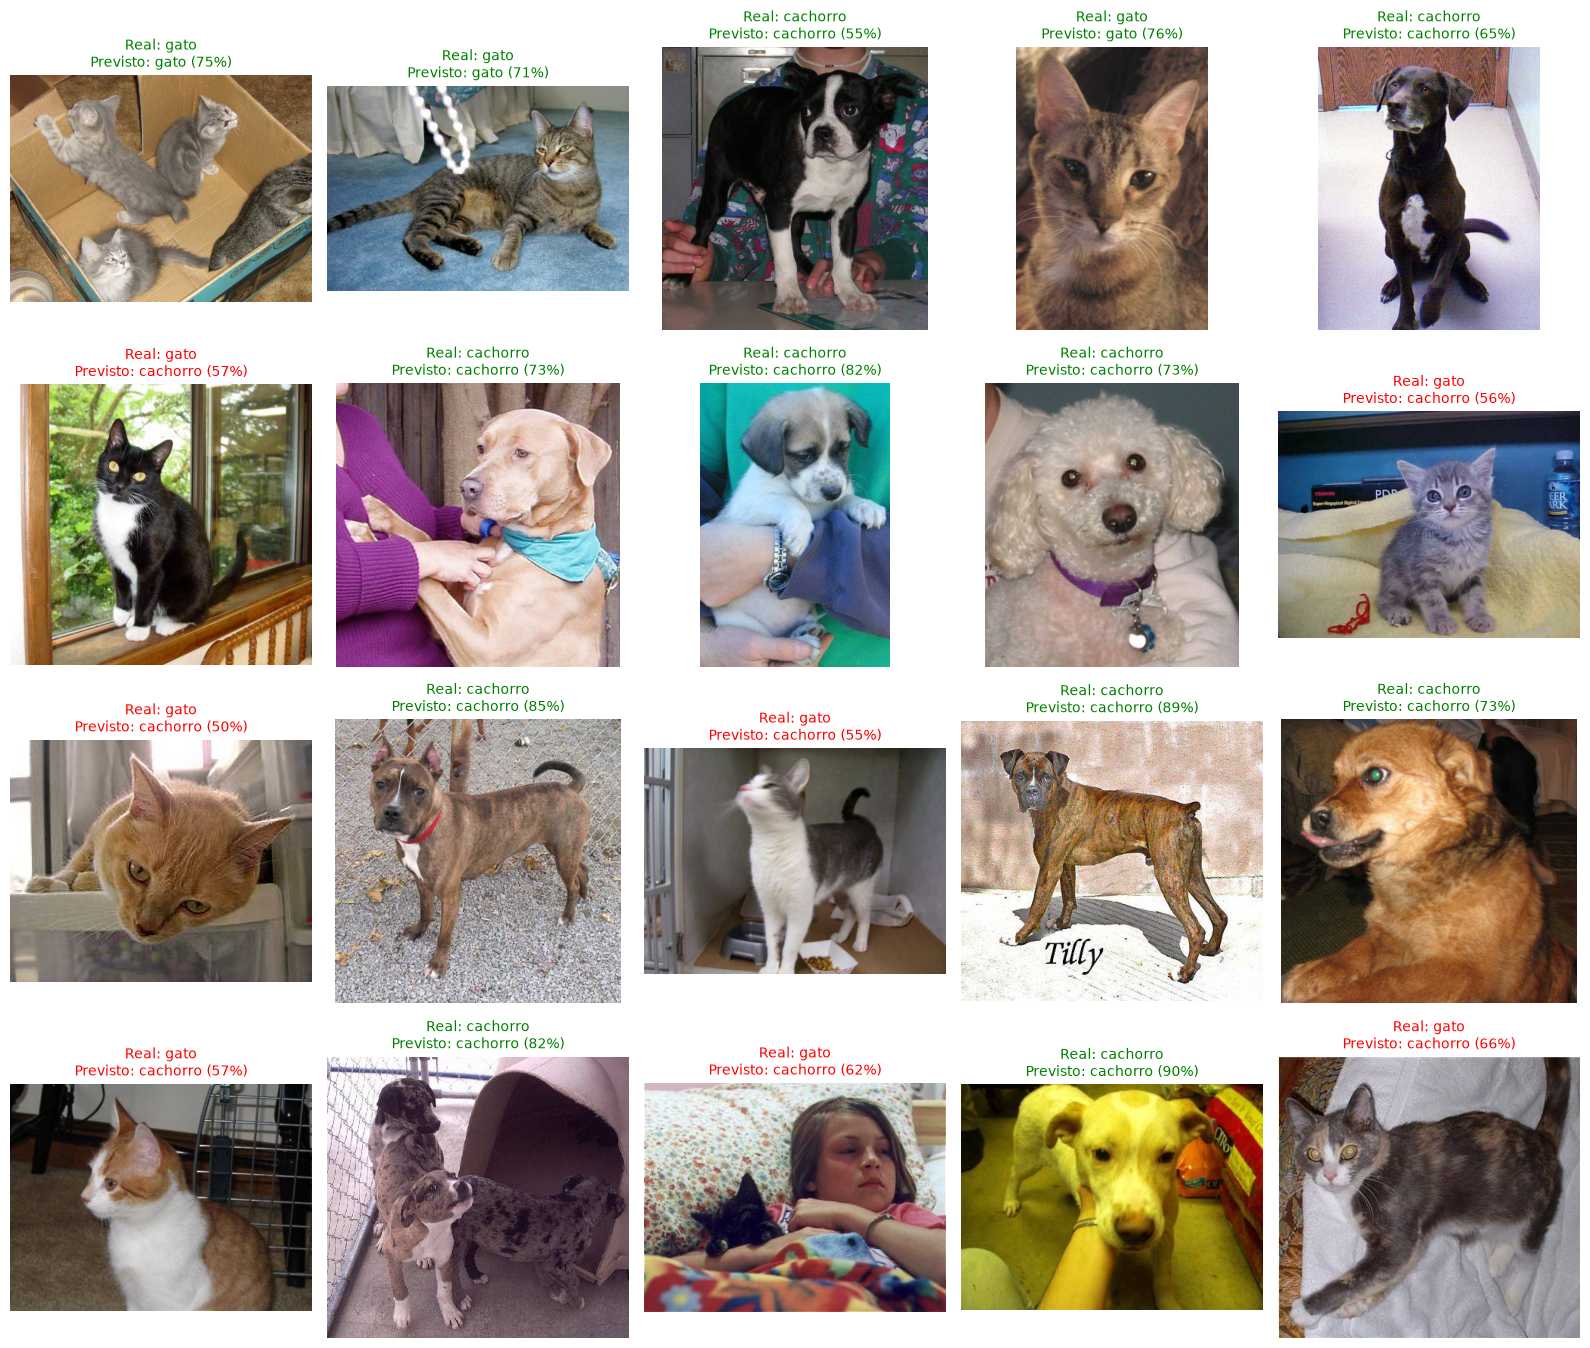

In [25]:
# Todas as suas imagens com a previsão da rede (verde = acerto, vermelho = erro)
mostrar_exemplos(base_minha, probs_minha, apenas_erros=False, quantidade=20)

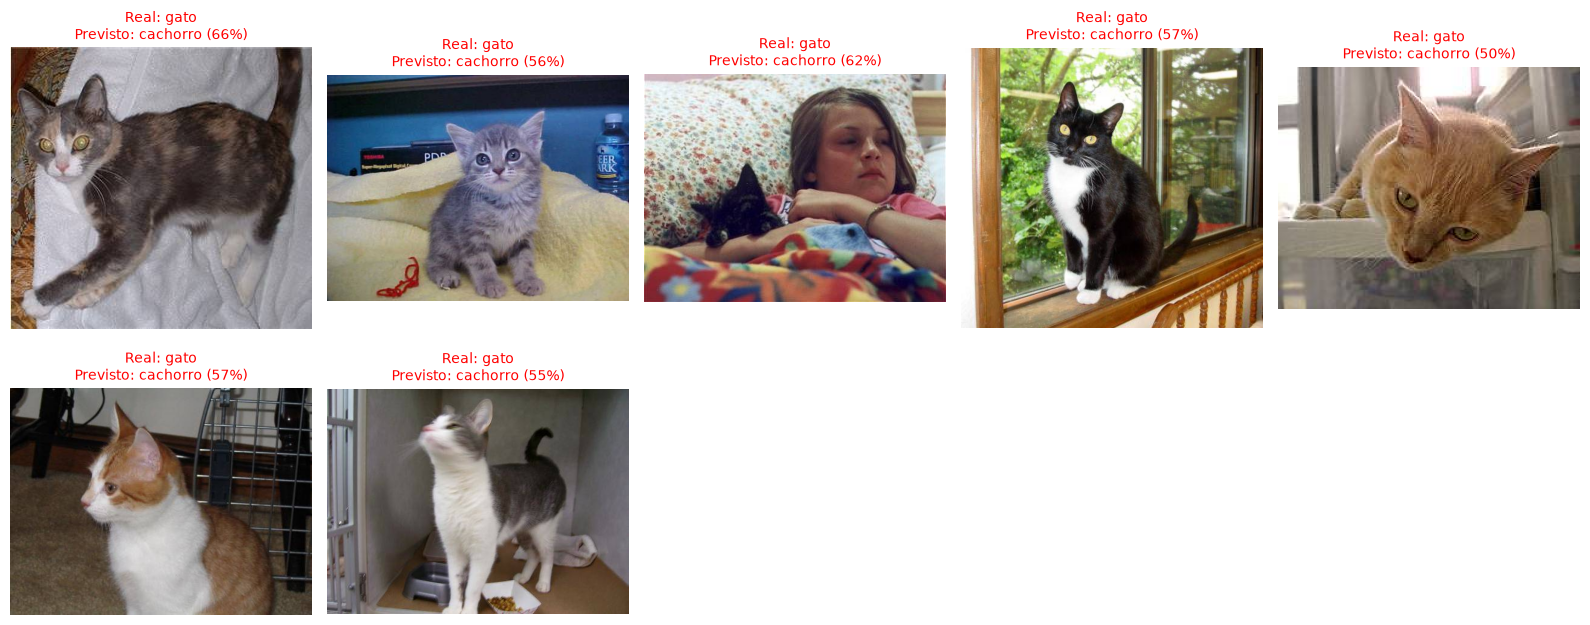

In [26]:
# Somente os erros — analise com atenção!
mostrar_exemplos(base_minha, probs_minha, apenas_erros=True, quantidade=20)

### Etapa 4 — Analise e discuta (relatório)
Responda no seu relatório:

1. Quais foram as métricas na **base de teste** e na **sua base**? Houve diferença? Por quê?
2. Observe as imagens que a rede **errou**. Existe algum padrão? (iluminação, distância, ângulo, fundo, raça, filhotes, mais de um animal, qualidade da câmera...)
3. Em quais erros a rede estava **muito confiante** (> 90%)? O que isso indica?
4. A sua base é parecida com a base de treino? O que acontece quando os dados reais são **diferentes** dos dados de treino?
   *(esse fenômeno se chama **mudança de distribuição** ou *domain shift*)*

### Relatório
Siga o **PDF de instruções do experimento** para montar o relatório: tabela com as 9 configurações, escolha do modelo, resultados na sua base e discussão.

**Entregar:** relatório em PDF + este notebook executado (`.ipynb`) + `minha_base.zip` + `resultados_experimento.csv`.